[OK] Plot successfully generated and saved to: figures/sim1_field_fluctuations.png


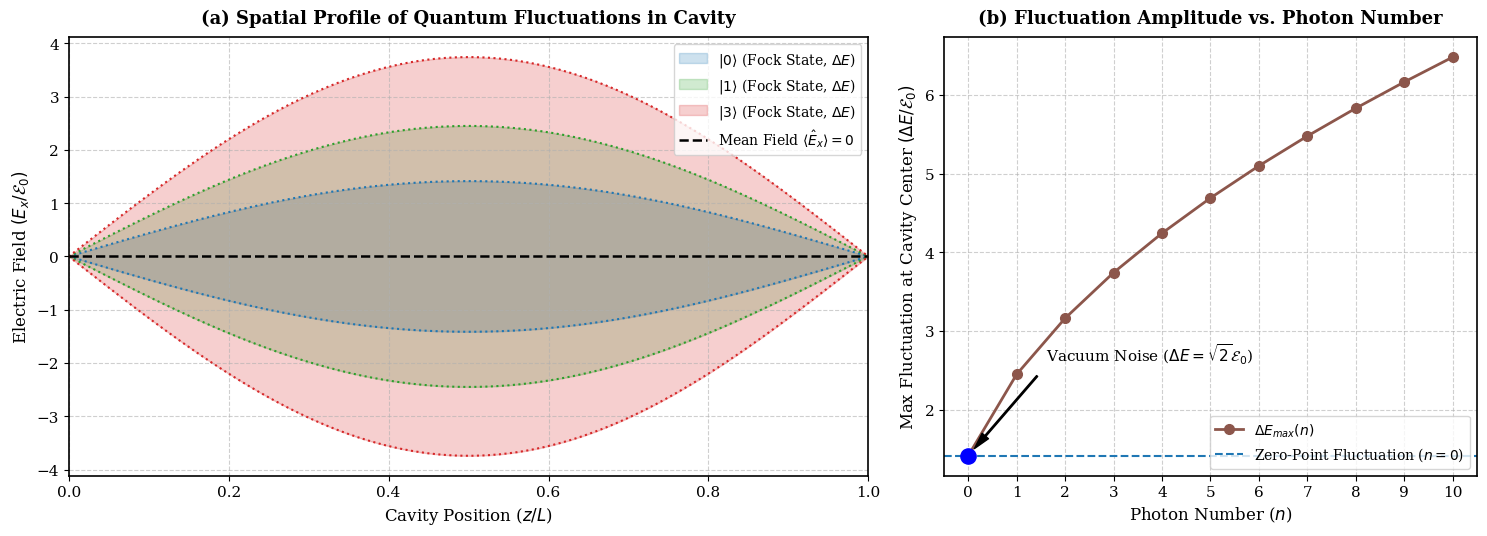

In [8]:
# ==============================================================================
# Simulation 1: Single-Mode Quantum Field Fluctuations & Vacuum Noise
# Reference: Gerry & Knight, "Introductory Quantum Optics", Chapter 2 (Eqs 2.22 - 2.26)
# ==============================================================================

import os
import numpy as np
import matplotlib.pyplot as plt

# Create output directory for figures (compatible with GitHub repository structure)
os.makedirs("figures", exist_ok=True)

# Plot styling configuration
plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.size'] = 11
plt.rcParams['axes.linewidth'] = 1.2

# -------------------------------------------------------------
# 1. Cavity and Physical Parameters
# -------------------------------------------------------------
L = 1.0           # Normalized cavity length
k = np.pi / L     # Fundamental mode wavevector (k = pi / L)
z = np.linspace(0, L, 1000)

# E_0: Field amplitude per photon (E_0 = sqrt(hbar * omega / (2 * epsilon_0 * V)))
E_0 = 1.0

# -------------------------------------------------------------
# 2. Theoretical Field Uncertainty Function
# -------------------------------------------------------------
def field_uncertainty(n, z_coord, E0=1.0, k_val=np.pi):
    r"""
    Calculate the standard deviation (quantum uncertainty) of the electric field:
    \Delta E_x(z) = 2 * E_0 * sqrt(n + 1/2) * |sin(kz)|
    """
    return 2.0 * E0 * np.sqrt(n + 0.5) * np.abs(np.sin(k_val * z_coord))

# -------------------------------------------------------------
# 3. Figure Setup and Plotting
# -------------------------------------------------------------
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={'width_ratios': [1.8, 1.2]})

# --- Subplot (a): Spatial Profile of Quantum Fluctuations ---
colors = ['#1f77b4', '#2ca02c', '#d62728']
fock_states = [0, 1, 3]

for n, col in zip(fock_states, colors):
    delta_E = field_uncertainty(n, z, E_0, k)
    
    # Fill uncertainty band around zero expectation value
    ax1.fill_between(z, -delta_E, delta_E, color=col, alpha=0.22,
                     label=rf'$|{n}\rangle$ (Fock State, $\Delta E$)')
    ax1.plot(z, delta_E, color=col, linestyle=':', linewidth=1.5)
    ax1.plot(z, -delta_E, color=col, linestyle=':', linewidth=1.5)

# Classical mean field expectation value is strictly zero
ax1.plot(z, np.zeros_like(z), 'k--', linewidth=1.8, label=r'Mean Field $\langle \hat{E}_x \rangle = 0$')

ax1.set_title(r'(a) Spatial Profile of Quantum Fluctuations in Cavity', fontsize=13, fontweight='bold', pad=10)
ax1.set_xlabel('Cavity Position ($z / L$)', fontsize=12)
ax1.set_ylabel(r'Electric Field $(E_x / \mathcal{E}_0)$', fontsize=12)
ax1.set_xlim(0, L)
ax1.grid(True, linestyle='--', alpha=0.6)
ax1.legend(loc='upper right', frameon=True, fontsize=10)

# --- Subplot (b): Quantum Fluctuation vs. Photon Number at Antinode ---
n_vals = np.arange(0, 11)
z_center = L / 2.0  # Center of cavity (antinode: |sin(kz)| = 1)
delta_E_center = field_uncertainty(n_vals, z_center, E_0, k)

ax2.plot(n_vals, delta_E_center, 'o-', color='#8c564b', markersize=7, linewidth=2, label=r'$\Delta E_{max}(n)$')
ax2.axhline(delta_E_center[0], color='#1f77b4', linestyle='--', linewidth=1.5, 
            label=r'Zero-Point Fluctuation ($n=0$)')

# Highlight the vacuum state (zero-point noise)
ax2.scatter([0], [delta_E_center[0]], color='blue', s=120, zorder=5)
ax2.annotate(r'Vacuum Noise ($\Delta E = \sqrt{2}\mathcal{E}_0$)', 
             xy=(0, delta_E_center[0]), xytext=(1.6, delta_E_center[0] + 1.2),
             arrowprops=dict(facecolor='black', shrink=0.08, width=1, headwidth=6))

ax2.set_title(r'(b) Fluctuation Amplitude vs. Photon Number', fontsize=13, fontweight='bold', pad=10)
ax2.set_xlabel('Photon Number ($n$)', fontsize=12)
ax2.set_ylabel(r'Max Fluctuation at Cavity Center $(\Delta E / \mathcal{E}_0)$', fontsize=12)
ax2.set_xticks(n_vals)
ax2.grid(True, linestyle='--', alpha=0.6)
ax2.legend(loc='lower right', frameon=True, fontsize=10)

plt.tight_layout()

# Save publication-quality figure to disk
output_path = "figures/sim1_field_fluctuations.png"
plt.savefig(output_path, dpi=300, bbox_inches='tight')
print(f"[OK] Plot successfully generated and saved to: {output_path}")

plt.show()